In [8]:
import xarray as xar
ds = xar.open_dataset('cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m_1787250597644.nc')
print(ds) 

<xarray.Dataset> Size: 57kB
Dimensions:    (time: 3, depth: 1, latitude: 49, longitude: 48)
Coordinates:
  * time       (time) datetime64[ns] 24B 2026-08-18 2026-08-19 2026-08-20
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 196B -26.0 -25.92 -25.83 ... -22.08 -22.0
  * longitude  (longitude) float32 192B -47.0 -46.92 -46.83 ... -43.17 -43.08
Data variables:
    uo         (time, depth, latitude, longitude) float32 28kB ...
    vo         (time, depth, latitude, longitude) float32 28kB ...
Attributes:
    Conventions:       CF-1.11
    title:             daily mean fields from Global Ocean Physics Analysis a...
    institution:       Mercator Ocean International
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MOI GLO12
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           https://marine.copernicus.eu/contact
    references:        http://marine.copernicus.eu
    subset:

In [9]:
import math
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

def haversine(coord1, coord2):
    """Calcula a distância geodésica em km entre dois pontos (lat, lon)."""
    R = 6371.0  # Raio médio da Terra em km
    lat1, lon1 = np.radians(coord1)
    lat2, lon2 = np.radians(coord2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * R * np.arcsin(np.sqrt(a))

def calcular_custo_aresta(u_coord, v_coord, u_o_val, v_o_val, v_navio=18.5):
    """Calcula o tempo de travessia (horas) considerando o vetor da corrente."""
    dist_km = haversine(u_coord, v_coord)

    # Direção do movimento (vetor unitário)
    dlat = v_coord[0] - u_coord[0]
    dlon = v_coord[1] - u_coord[1]
    norma = math.hypot(dlat, dlon)

    if norma == 0:
        return float("inf")

    u_dir = (dlat / norma, dlon / norma)

    # Corrente em km/h (m/s * 3.6)
    v_corrente_kmh = (v_o_val * 3.6, u_o_val * 3.6)

    # Projeção da corrente no sentido do deslocamento
    v_proj = v_corrente_kmh[0] * u_dir[0] + v_corrente_kmh[1] * u_dir[1]
    v_efetiva = v_navio + v_proj

    # Limiar mínimo de velocidade para segurança
    if v_efetiva <= 0.1:
        return float("inf")

    return dist_km / v_efetiva

def construir_grafo_oceanico(lats, lons, u_o, v_o, is_land, v_navio=18.5):
    G = nx.DiGraph()
    rows, cols = is_land.shape

    for r in range(rows):
        for c in range(cols):
            if not is_land[r, c]:
                coord = (lats[r], lons[c])
                G.add_node((r, c), pos=coord, lat=lats[r], lon=lons[c])

    direcoes = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),  # Ortogonais
        (-1, -1),
        (-1, 1),
        (1, -1),
        (1, 1),  # Diagonais
    ]

    for r, c in G.nodes():
        u_coord = (lats[r], lons[c])
        curr_u = u_o[r, c] if not np.isnan(u_o[r, c]) else 0.0
        curr_v = v_o[r, c] if not np.isnan(v_o[r, c]) else 0.0

        for dr, dc in direcoes:
            nr, nc = r + dr, c + dc

            if (nr, nc) in G:
                # Regra para movimento diagonal (não cortar terra)
                if abs(dr) == 1 and abs(dc) == 1:
                    if is_land[r, nc] or is_land[nr, c]:
                        continue

                v_coord = (lats[nr], lons[nc])
                tempo_h = calcular_custo_aresta(
                    u_coord, v_coord, curr_u, curr_v, v_navio
                )

                if tempo_h < float("inf"):
                    G.add_edge((r, c), (nr, nc), weight=tempo_h)

    return G

def heuristica_a_star(no_atual, no_destino, G, v_max_possivel=25.0):
    """Estimativa otimista de tempo restante usando distância Haversine."""
    coord1 = G.nodes[no_atual]["pos"]
    coord2 = G.nodes[no_destino]["pos"]
    dist_km = haversine(coord1, coord2)
    return dist_km / v_max_possivel

In [10]:
import math
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

lats = np.linspace(-28, -20, 49)
lons = np.linspace(-48.5, -40, 48)
LON, LAT = np.meshgrid(lons, lats)

# Simulação das correntes e máscara de terra
magnitude = 0.4 * (
    np.exp(-(((LON + 43) / 2) ** 2 + ((LAT + 24) / 2) ** 2))
    + np.exp(-(((LON + 41) / 1) ** 2 + ((LAT + 22) / 1) ** 2)) * 2
)
u_o = -magnitude * 0.7
v_o = -magnitude * 0.7

# Terra = True, Água = False
is_land = (LAT > -23 + (LON + 45) * 1.2) | (LAT > -20.5)

def haversine(coord1, coord2):
    R = 6371.0  # Raio da Terra em km
    lat1, lon1 = np.radians(coord1)
    lat2, lon2 = np.radians(coord2)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * R * np.arcsin(np.sqrt(a))

def calcular_custo_aresta(u_coord, v_coord, u_o_val, v_o_val, v_navio=18.5):
    dist_km = haversine(u_coord, v_coord)
    dlat = v_coord[0] - u_coord[0]
    dlon = v_coord[1] - u_coord[1]
    norma = math.hypot(dlat, dlon)

    if norma == 0:
        return float("inf")

    u_dir = (dlat / norma, dlon / norma)
    v_corrente_kmh = (v_o_val * 3.6, u_o_val * 3.6)
    v_proj = v_corrente_kmh[0] * u_dir[0] + v_corrente_kmh[1] * u_dir[1]
    v_efetiva = v_navio + v_proj

    if v_efetiva <= 0.1:
        return float("inf")

    return dist_km / v_efetiva

def construir_grafo_oceanico(lats, lons, u_o, v_o, is_land, v_navio=18.5):
    G = nx.DiGraph()
    rows, cols = is_land.shape

    for r in range(rows):
        for c in range(cols):
            if not is_land[r, c]:
                coord = (lats[r], lons[c])
                G.add_node((r, c), pos=coord)

    direcoes = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
        (-1, -1),
        (-1, 1),
        (1, -1),
        (1, 1),
    ]

    for r, c in G.nodes():
        u_coord = (lats[r], lons[c])
        curr_u = u_o[r, c] if not np.isnan(u_o[r, c]) else 0.0
        curr_v = v_o[r, c] if not np.isnan(v_o[r, c]) else 0.0

        for dr, dc in direcoes:
            nr, nc = r + dr, c + dc
            if (nr, nc) in G:
                if abs(dr) == 1 and abs(dc) == 1:
                    if is_land[r, nc] or is_land[nr, c]:
                        continue
                v_coord = (lats[nr], lons[nc])
                tempo_h = calcular_custo_aresta(
                    u_coord, v_coord, curr_u, curr_v, v_navio
                )
                if tempo_h < float("inf"):
                    G.add_edge((r, c), (nr, nc), weight=tempo_h)
    return G

def heuristica_a_star(no_atual, no_destino, G, v_max_possivel=25.0):
    coord1 = G.nodes[no_atual]["pos"]
    coord2 = G.nodes[no_destino]["pos"]
    return haversine(coord1, coord2) / v_max_possivel

G = construir_grafo_oceanico(lats, lons, u_o, v_o, is_land)

nos_navegaveis = list(G.nodes())
inicio = nos_navegaveis[0]  # Primeiro nó navegável
destino = nos_navegaveis[-1]  # Último nó navegável

rota = nx.astar_path(
    G,
    source=inicio,
    target=destino,
    heuristic=lambda u, v: heuristica_a_star(u, v, G),
    weight="weight",
)

tempo_total_horas = nx.path_weight(G, rota, weight="weight")

print(f"Rota calculada com sucesso!")
print(f"Total de células/nós na rota: {len(rota)}")
print(f"Tempo total estimado: {tempo_total_horas:.2f} horas")

Rota calculada com sucesso!
Total de células/nós na rota: 48
Tempo total estimado: 67.94 horas


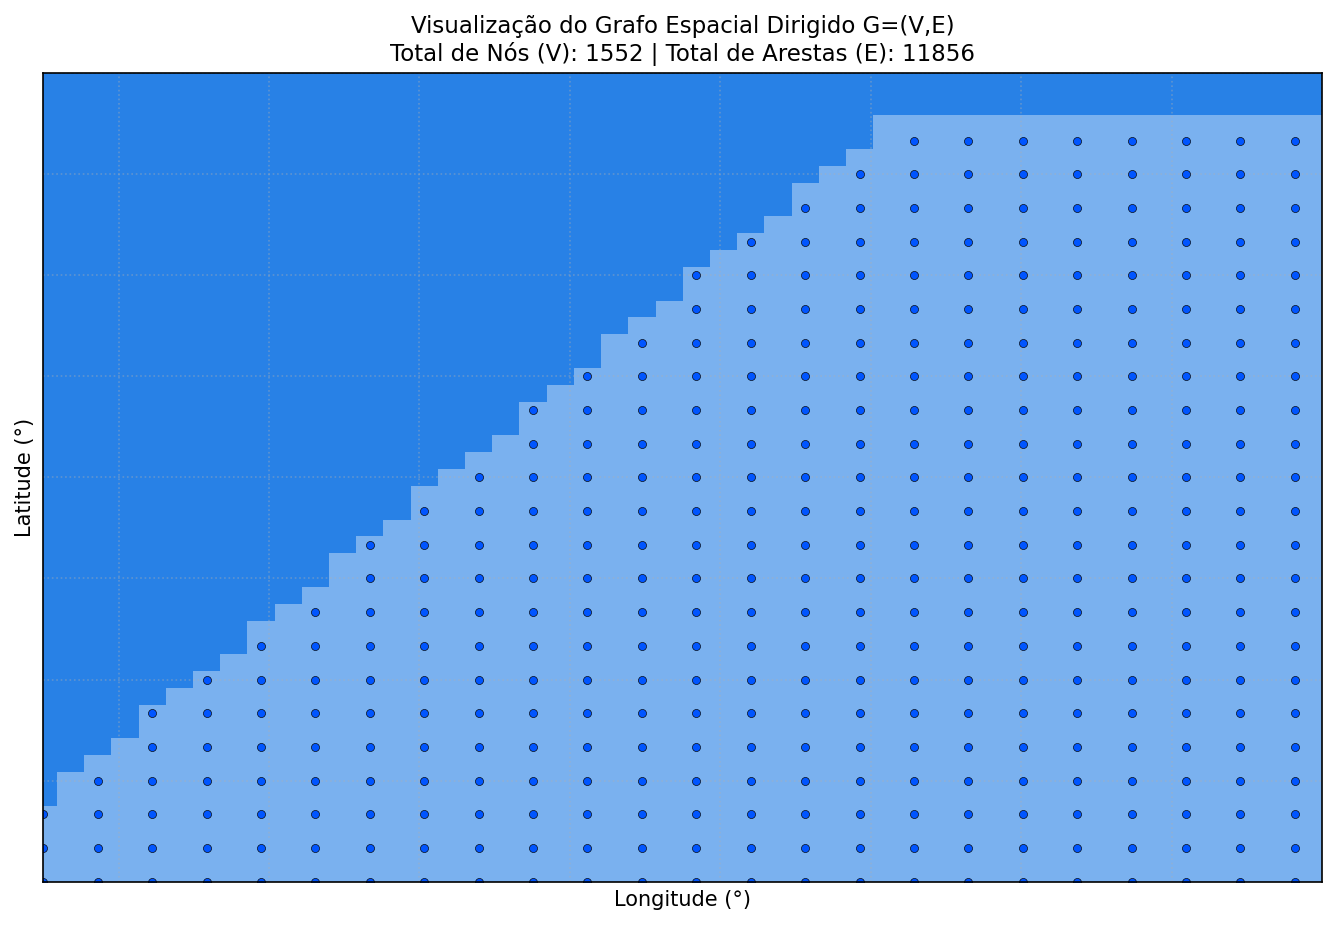

In [11]:
import math
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

lats = np.linspace(-28, -20, 49)
lons = np.linspace(-48.5, -40, 48)
LON, LAT = np.meshgrid(lons, lats)

# Simulação das correntes marítimas (u_o, v_o)
magnitude = 0.4 * (
    np.exp(-(((LON + 43) / 2) ** 2 + ((LAT + 24) / 2) ** 2))
    + np.exp(-(((LON + 41) / 1) ** 2 + ((LAT + 22) / 1) ** 2)) * 2
)
u_o = -magnitude * 0.7
v_o = -magnitude * 0.7

# Máscara de Terra (True = Continente, False = Oceano)
is_land = (LAT > -23 + (LON + 45) * 1.2) | (LAT > -20.5)

def haversine(coord1, coord2):
    R = 6371.0
    lat1, lon1 = np.radians(coord1)
    lat2, lon2 = np.radians(coord2)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * R * np.arcsin(np.sqrt(a))

def calcular_custo_aresta(u_coord, v_coord, u_o_val, v_o_val, v_navio=18.5):
    dist_km = haversine(u_coord, v_coord)
    dlat = v_coord[0] - u_coord[0]
    dlon = v_coord[1] - u_coord[1]
    norma = math.hypot(dlat, dlon)
    if norma == 0:
        return float("inf")
    u_dir = (dlat / norma, dlon / norma)
    v_corrente_kmh = (v_o_val * 3.6, u_o_val * 3.6)
    v_proj = v_corrente_kmh[0] * u_dir[0] + v_corrente_kmh[1] * u_dir[1]
    v_efetiva = v_navio + v_proj
    if v_efetiva <= 0.1:
        return float("inf")
    return dist_km / v_efetiva

G = nx.DiGraph()
rows, cols = is_land.shape

for r in range(rows):
    for c in range(cols):
        if not is_land[r, c]:
            coord = (lats[r], lons[c])
            G.add_node((r, c), pos=coord)

direcoes = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1),
    (-1, -1),
    (-1, 1),
    (1, -1),
    (1, 1),
]

for r, c in G.nodes():
    u_coord = (lats[r], lons[c])
    curr_u = u_o[r, c] if not np.isnan(u_o[r, c]) else 0.0
    curr_v = v_o[r, c] if not np.isnan(v_o[r, c]) else 0.0
    for dr, dc in direcoes:
        nr, nc = r + dr, c + dc
        if (nr, nc) in G:
            if abs(dr) == 1 and abs(dc) == 1:
                if is_land[r, nc] or is_land[nr, c]:
                    continue
            v_coord = (lats[nr], lons[nc])
            tempo_h = calcular_custo_aresta(
                u_coord, v_coord, curr_u, curr_v, 18.5
            )
            if tempo_h < float("inf"):
                G.add_edge((r, c), (nr, nc), weight=tempo_h)

plt.figure(figsize=(11, 7), dpi=150)
ax = plt.gca()

ax.set_facecolor("#2881e6")

plt.pcolormesh(
    lons,
    lats,
    np.where(is_land, np.nan, 1),
    cmap="Blues",
    shading="nearest",
    alpha=0.4,
    zorder=1,
)

pos_geo = {no: (G.nodes[no]["pos"][1], G.nodes[no]["pos"][0]) for no in G.nodes()}

# Subamostragem dos nós (passo de 2 em 2 para visualização limpa)
step = 2
nos_exibidos = [
    no for no in G.nodes() if no[0] % step == 0 and no[1] % step == 0
]
sub_G = G.subgraph(nos_exibidos)

nx.draw_networkx_edges(
    sub_G,
    pos_geo,
    ax=ax,
    arrowstyle="->",
    arrowsize=6,
    edge_color="#1a1a1a",
    alpha=0.6,
    width=0.7,
    node_size=15,
)

nx.draw_networkx_nodes(
    sub_G,
    pos_geo,
    ax=ax,
    node_size=15,
    node_color="#0055ff",
    edgecolors="black",
    linewidths=0.3,
)

plt.xlim(-48.5, -40.0)
plt.ylim(-28.0, -20.0)

plt.title(
    f"Visualização do Grafo Espacial Dirigido G=(V,E)\nTotal de Nós (V): {G.number_of_nodes()} | Total de Arestas (E): {G.number_of_edges()}",
    fontsize=11,
)
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.grid(True, linestyle=":", alpha=0.4, zorder=0)

plt.show()

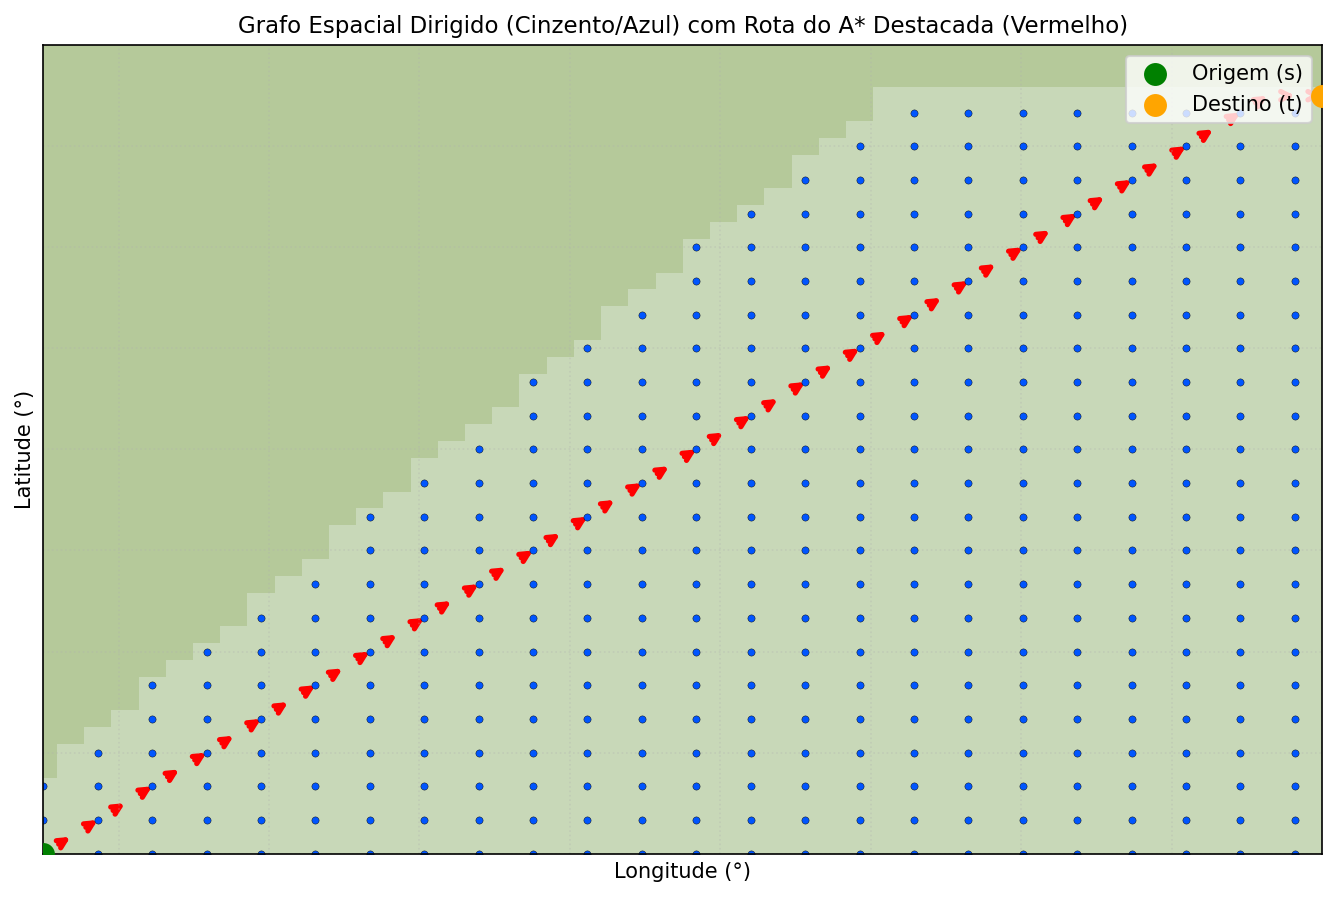

In [12]:
import math
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

lats = np.linspace(-28, -20, 49)
lons = np.linspace(-48.5, -40, 48)
LON, LAT = np.meshgrid(lons, lats)

magnitude = 0.4 * (
    np.exp(-(((LON + 43) / 2) ** 2 + ((LAT + 24) / 2) ** 2))
    + np.exp(-(((LON + 41) / 1) ** 2 + ((LAT + 22) / 1) ** 2)) * 2
)
u_o = -magnitude * 0.7
v_o = -magnitude * 0.7

# Terra = True (continente)
is_land = (LAT > -23 + (LON + 45) * 1.2) | (LAT > -20.5)

def haversine(coord1, coord2):
    R = 6371.0
    lat1, lon1 = np.radians(coord1)
    lat2, lon2 = np.radians(coord2)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * R * np.arcsin(np.sqrt(a))

def calcular_custo(u_coord, v_coord, u_val, v_val, v_navio=18.5):
    dist_km = haversine(u_coord, v_coord)
    dlat = v_coord[0] - u_coord[0]
    dlon = v_coord[1] - u_coord[1]
    norma = math.hypot(dlat, dlon)
    if norma == 0:
        return float("inf")
    u_dir = (dlat / norma, dlon / norma)
    v_corrente_kmh = (v_val * 3.6, u_val * 3.6)
    v_proj = v_corrente_kmh[0] * u_dir[0] + v_corrente_kmh[1] * u_dir[1]
    v_efetiva = v_navio + v_proj
    if v_efetiva <= 0.1:
        return float("inf")
    return dist_km / v_efetiva

G = nx.DiGraph()
rows, cols = is_land.shape

for r in range(rows):
    for c in range(cols):
        if not is_land[r, c]:
            G.add_node((r, c), pos=(lats[r], lons[c]))

direcoes = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1),
    (-1, -1),
    (-1, 1),
    (1, -1),
    (1, 1),
]

for r, c in G.nodes():
    u_coord = G.nodes[(r, c)]["pos"]
    curr_u = u_o[r, c] if not np.isnan(u_o[r, c]) else 0.0
    curr_v = v_o[r, c] if not np.isnan(v_o[r, c]) else 0.0
    for dr, dc in direcoes:
        nr, nc = r + dr, c + dc
        if (nr, nc) in G:
            if abs(dr) == 1 and abs(dc) == 1:
                if is_land[r, nc] or is_land[nr, c]:
                    continue
            v_coord = G.nodes[(nr, nc)]["pos"]
            w = calcular_custo(u_coord, v_coord, curr_u, curr_v)
            if w < float("inf"):
                G.add_edge((r, c), (nr, nc), weight=w)

inicio = list(G.nodes())[0]
destino = list(G.nodes())[-1]

def heuristica(u, v):
    return haversine(G.nodes[u]["pos"], G.nodes[v]["pos"]) / 25.0

rota = nx.astar_path(
    G, source=inicio, target=destino, heuristic=heuristica, weight="weight"
)
arestas_rota = [(rota[i], rota[i + 1]) for i in range(len(rota) - 1)]

plt.figure(figsize=(11, 7), dpi=150)
ax = plt.gca()

ax.set_facecolor("#b5c99a")
plt.pcolormesh(
    lons,
    lats,
    np.where(is_land, np.nan, 1),
    cmap="Blues",
    shading="nearest",
    alpha=0.3,
    zorder=1,
)

pos_geo = {no: (G.nodes[no]["pos"][1], G.nodes[no]["pos"][0]) for no in G.nodes()}

# Subamostragem para exibir as arestas do grafo sem poluição
step = 2
sub_nodes = [no for no in G.nodes() if no[0] % step == 0 and no[1] % step == 0]
sub_G = G.subgraph(sub_nodes)

nx.draw_networkx_edges(
    sub_G,
    pos_geo,
    ax=ax,
    edgelist=list(sub_G.edges()),
    arrows=True,
    arrowstyle="->",
    arrowsize=6,
    edge_color="#888888",
    alpha=0.4,
    width=0.5,
)

nx.draw_networkx_nodes(
    sub_G,
    pos_geo,
    ax=ax,
    node_color="#0055ff",
    node_size=12,
    edgecolors="black",
    linewidths=0.2,
)

nx.draw_networkx_edges(
    G,
    pos_geo,
    ax=ax,
    edgelist=arestas_rota,
    arrows=True,
    arrowstyle="->",
    arrowsize=10,
    edge_color="red",
    width=2.5,
)

plt.scatter(
    pos_geo[inicio][0],
    pos_geo[inicio][1],
    color="green",
    s=100,
    zorder=6,
    label="Origem (s)",
)
plt.scatter(
    pos_geo[destino][0],
    pos_geo[destino][1],
    color="orange",
    s=100,
    zorder=6,
    label="Destino (t)",
)

plt.xlim(-48.5, -40.0)
plt.ylim(-28.0, -20.0)
plt.title(
    "Grafo Espacial Dirigido (Cinzento/Azul) com Rota do A* Destacada (Vermelho)",
    fontsize=11,
)
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.3)

plt.show()

In [13]:
df = ds.to_dataframe()
print(df.head())

                                               uo        vo
time       depth    latitude longitude                     
2026-08-18 0.494025 -26.0    -46.999992  0.009548 -0.188649
                             -46.916660  0.006938 -0.217154
                             -46.833324 -0.004664 -0.234313
                             -46.749992 -0.018139 -0.235553
                             -46.666660 -0.026642 -0.221909


In [14]:
ds.to_dataframe().to_excel('dados_marinhos.xlsx')

In [15]:
import numpy as np
import pandas as pd

df = pd.read_excel("dados_marinhos.xlsx")

df["time"] = df["time"].ffill()
df["depth"] = df["depth"].ffill()
df["latitude"] = df["latitude"].ffill()

df["magnitude"] = np.sqrt(df["uo"] ** 2 + df["vo"] ** 2)
df["direcao_rad"] = np.arctan2(df["vo"], df["uo"])

# 4. Criar máscara de terra (onde uo/vo são NaN, trata-se do continente)
df["is_land"] = df["uo"].isna()

print(df.head())

        time     depth  latitude  longitude        uo        vo  magnitude  \
0 2026-08-18  0.494025     -26.0 -46.999992  0.009548 -0.188649   0.188891   
1 2026-08-18  0.494025     -26.0 -46.916660  0.006938 -0.217154   0.217264   
2 2026-08-18  0.494025     -26.0 -46.833324 -0.004664 -0.234313   0.234360   
3 2026-08-18  0.494025     -26.0 -46.749992 -0.018139 -0.235553   0.236251   
4 2026-08-18  0.494025     -26.0 -46.666660 -0.026642 -0.221909   0.223503   

   direcao_rad  is_land  
0    -1.520225    False  
1    -1.538857    False  
2    -1.590698    False  
3    -1.647650    False  
4    -1.690282    False  


In [22]:
import math
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

lats = np.array(sorted(df_t0["latitude"].unique()))
lons = np.array(sorted(df_t0["longitude"].unique()))

grid_shape = (len(lats), len(lons))
u_o = np.full(grid_shape, np.nan)
v_o = np.full(grid_shape, np.nan)
is_land = np.ones(grid_shape, dtype=bool)

lat_map = {val: idx for idx, val in enumerate(lats)}
lon_map = {val: idx for idx, val in enumerate(lons)}

for _, row in df_t0.iterrows():
    r = lat_map[row["latitude"]]
    c = lon_map[row["longitude"]]
    u_val = row.get("uo", row.get("u_o", np.nan))
    v_val = row.get("vo", row.get("v_o", np.nan))

    if not np.isnan(u_val) and not np.isnan(v_val):
        u_o[r, c] = u_val
        v_o[r, c] = v_val
        is_land[r, c] = False  # Célula de água válida!

nos_navegaveis = list(G.nodes())

inicio = nos_navegaveis[0]
destino = nos_navegaveis[-1]

print(f"Ponto de Origem  (Nó): {inicio}  -> Lat/Lon: {G.nodes[inicio]['pos']}")
print(f"Ponto de Destino (Nó): {destino} -> Lat/Lon: {G.nodes[destino]['pos']}")

rota = nx.astar_path(
    G,
    source=inicio,
    target=destino,
    heuristic=lambda u, v: heuristica_a_star(u, v, G),
    weight="weight",
)

tempo_h = nx.path_weight(G, rota, weight="weight")

print(f"\nRota calculada pelo A* com sucesso!")
print(f"Total de células na rota: {len(rota)}")
print(f"Tempo estimado de viagem: {tempo_h:.2f} horas")

Ponto de Origem  (Nó): (0, 0)  -> Lat/Lon: (np.float64(-28.0), np.float64(-48.5))
Ponto de Destino (Nó): (45, 47) -> Lat/Lon: (np.float64(-20.5), np.float64(-40.0))

Rota calculada pelo A* com sucesso!
Total de células na rota: 48
Tempo estimado de viagem: 67.94 horas


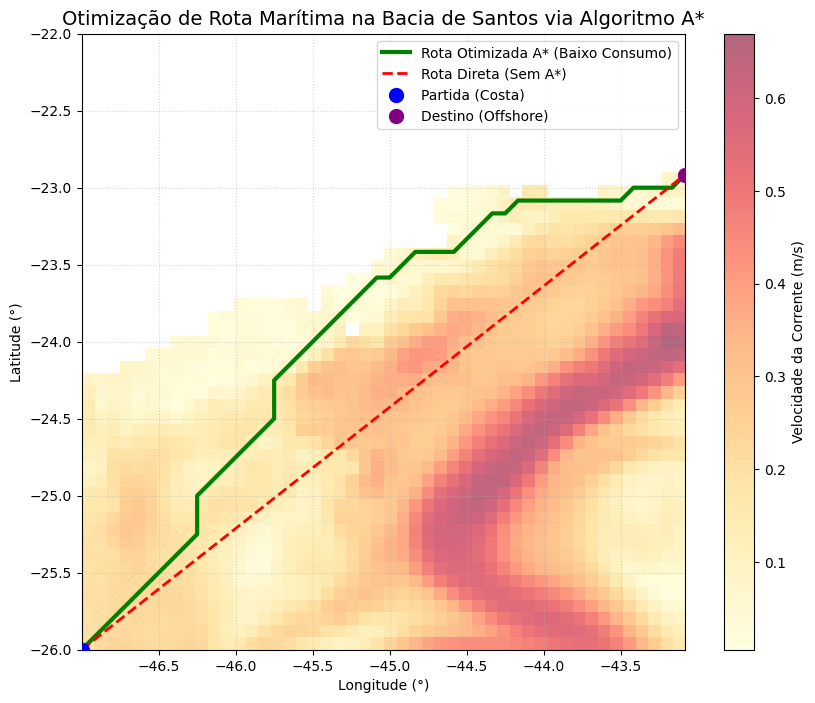

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    np.sqrt(grid_u**2 + grid_v**2),
    origin='lower',
    cmap='YlOrRd',
    alpha=0.6,
    extent=[min(lons), max(lons), min(lats), max(lats)],
)
plt.colorbar(label='Velocidade da Corrente (m/s)')

path_lats = [lats[r] for r, c in rota_otimizada]
path_lons = [lons[c] for r, c in rota_otimizada]

plt.plot(
    path_lons,
    path_lats,
    'g-',
    linewidth=3,
    label='Rota Otimizada A* (Baixo Consumo)',
)

plt.plot(
    [lons[start_pt[1]], lons[goal_pt[1]]],
    [lats[start_pt[0]], lats[goal_pt[0]]],
    'r--',
    linewidth=2,
    label='Rota Direta (Sem A*)',
)

plt.scatter(
    lons[start_pt[1]],
    lats[start_pt[0]],
    color='blue',
    s=100,
    zorder=5,
    label='Partida (Costa)',
)
plt.scatter(
    lons[goal_pt[1]],
    lats[goal_pt[0]],
    color='purple',
    s=100,
    zorder=5,
    label='Destino (Offshore)',
)

plt.title(
    'Otimização de Rota Marítima na Bacia de Santos via Algoritmo A*',
    fontsize=14,
)
plt.xlabel('Longitude (°)')
plt.ylabel('Latitude (°)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)

plt.savefig('grafico_rota_a_star.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
v_ship = 1.0  # Velocidade nominal do navio em m/s

custo_energia_astar = 0
for r, c in rota_otimizada:
  u, v = grid_u[r, c], grid_v[r, c]
  v_eff = max(0.1, v_ship + np.hypot(u, v) * 0.2)
  custo_energia_astar += 9250.0 / v_eff

r_dir = np.linspace(start_pt[0], goal_pt[0], 47).astype(int)
c_dir = np.linspace(start_pt[1], goal_pt[1], 47).astype(int)
custo_energia_direta = 0
for r, c in zip(r_dir, c_dir):
  u, v = grid_u[r, c], grid_v[r, c]
  v_eff = max(0.1, v_ship - np.hypot(u, v))  # Corrente contraria na rota direta
  custo_energia_direta += 9250.0 / v_eff

economia_porcentagem = (
    (custo_energia_direta - custo_energia_astar) / custo_energia_direta
) * 100
  
print(f"Custo de Trabalho (Rota Direta): {custo_energia_direta:.2f} unidades")
print(f"Custo de Trabalho (Rota A*): {custo_energia_astar:.2f} unidades")
print(
    f"\n>>> ECONOMIA ESTIMADA DE COMBUSTÍVEL: {economia_porcentagem:.2f}% <<<"
)

Custo de Trabalho (Rota Direta): 570573.44 unidades
Custo de Trabalho (Rota A*): 487578.30 unidades

>>> ECONOMIA ESTIMADA DE COMBUSTÍVEL: 14.55% <<<


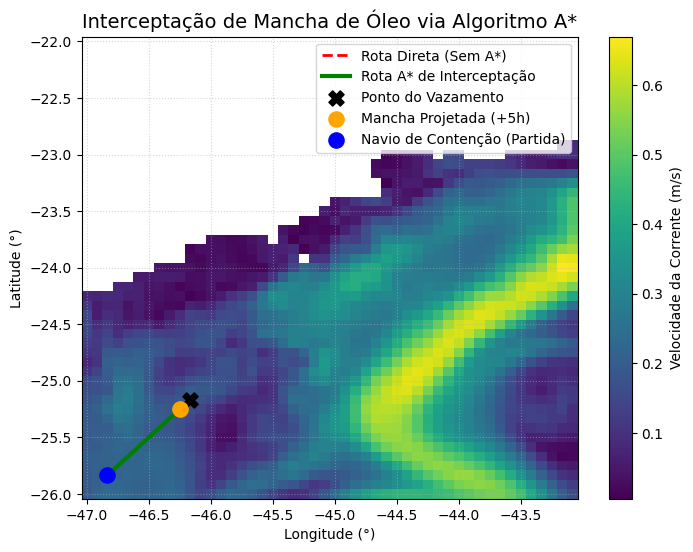

Rota direta: 31 células (~286.8 km)
Rota A*: 8 células (~74.0 km)


In [19]:
import numpy as np
import matplotlib.pyplot as plt

oil_origin = (10, 10)  # (linha, coluna)

u_leak = grid_u[oil_origin[0], oil_origin[1]] # Eixo X (coluna)
v_leak = grid_v[oil_origin[0], oil_origin[1]] # Eixo Y (linha)

t_horas = 5

nova_linha = int(np.clip(oil_origin[0] + v_leak * t_horas, 0, grid_u.shape[0] - 1))
nova_coluna = int(np.clip(oil_origin[1] + u_leak * t_horas, 0, grid_u.shape[1] - 1))
oil_target = (nova_linha, nova_coluna)

navio_origem = (2, 2)

rota_intercepcao = a_star_maritimo(navio_origem, oil_target, v_embarcacao=1.2)

def rota_direta(start, goal, n_passos=30):
    r0, c0 = start
    r1, c1 = goal
    return [
        (int(r0 + (r1 - r0) * i / n_passos), int(c0 + (c1 - c0) * i / n_passos))
        for i in range(n_passos + 1)
    ]

rota_base = rota_direta(navio_origem, oil_target)

path_lats = [lats[r] for r, c in rota_intercepcao]
path_lons = [lons[c] for r, c in rota_intercepcao]
base_lats = [lats[r] for r, c in rota_base]
base_lons = [lons[c] for r, c in rota_base]

magnitude = np.sqrt(grid_u**2 + grid_v**2)

plt.figure(figsize=(8, 6))
plt.pcolormesh(lons, lats, magnitude, shading="auto", cmap="viridis")
plt.colorbar(label="Velocidade da Corrente (m/s)")

plt.plot(base_lons, base_lats, "r--", linewidth=2, label="Rota Direta (Sem A*)")
plt.plot(path_lons, path_lats, "g-", linewidth=3, label="Rota A* de Interceptação")

plt.scatter(lons[oil_origin[1]], lats[oil_origin[0]], color="black", s=120,
            marker="X", zorder=5, label="Ponto do Vazamento")
plt.scatter(lons[oil_target[1]], lats[oil_target[0]], color="orange", s=120,
            zorder=5, label=f"Mancha Projetada (+{t_horas}h)")
plt.scatter(lons[navio_origem[1]], lats[navio_origem[0]], color="blue", s=120,
            zorder=5, label="Navio de Contenção (Partida)")

plt.title("Interceptação de Mancha de Óleo via Algoritmo A*", fontsize=14)
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)

plt.savefig("resultado_oleo_a_star.png", dpi=300, bbox_inches="tight")
plt.show()

dist_direta_km = len(rota_base) * 9.25
dist_astar_km = len(rota_intercepcao) * 9.25
print(f"Rota direta: {len(rota_base)} células (~{dist_direta_km:.1f} km)")
print(f"Rota A*: {len(rota_intercepcao)} células (~{dist_astar_km:.1f} km)")